Project Title: Visualization of Brain Activity in Emotion Regulation
Author: Iris Onderwater
Date: 26/11/2026
Link: https://neurosynth.org/analyses/terms/emotion%20regulation/

1. Importing Packages
Glob is needed for locating the MRI files. 
Nibabel	is needed for loading MRI images and extracting voxel values. 
Nilearn	is needed for visualization of brain data.
Matplotlib is needed for creating a histogram. 

In [1]:
import nilearn 
import nibabel
import matplotlib 
import glob #Import the needed packages

2. Locating to the MRI files 
Here glob is used to automatically find all files
with the .nii.gz extension in the working directory.

In [2]:
files = glob.glob('*.nii.gz') #Find all files with .nii.gz 
print(files) #Print to check if both files are found

['emotion regulation_uniformity-test_z_FDR_0.01.nii.gz', 'anatomical.nii.gz']


3. Identifying files
Here a for loop is used to look through the list of filenames.
To distuingish between the anatomical data and uniformity data an conditional statement is made. Then the files are saved in different variables. 

In [3]:
for file in files: #Loop through the list of filenames
    if 'anatomical' in file: #Check if the file contains anatomical data
        anatomical_file = file
    elif 'uniformity' in file: #Check if the file contains uniformity data
        uniformity_file = file

print(anatomical_file) #Print to check if they are found
print(uniformity_file)

anatomical.nii.gz
emotion regulation_uniformity-test_z_FDR_0.01.nii.gz


4. Loading MRI images
Both the anatomical data and the uniformity data are
loaded using Nibabel. This converts the files into image
objects. These are needed for later visualization.

In [4]:
anatomical_image = nibabel.load(anatomical_file) #Load both MRI files as image objects for later visualization
uniformity_image = nibabel.load(uniformity_file)

In [5]:
from nilearn import plotting #needed for plotting data

5. Visualizing the brain map
The uniformity test map is displayed on top of the
anatomical brain image using Nilearn. The hot colormap
is used to visualize the statistical Z-scores, with a
visualization threshold of 0.1.

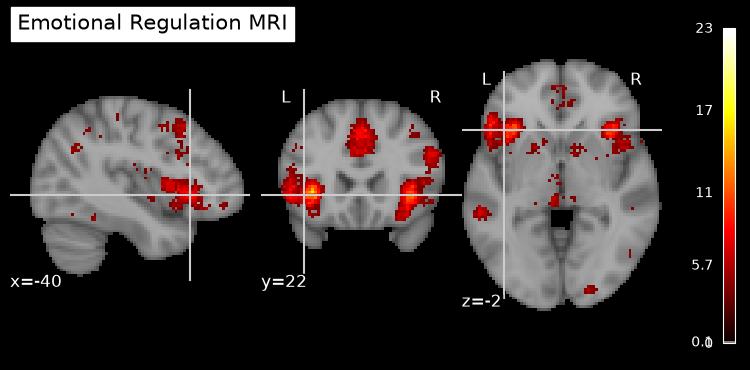

In [6]:
plotting.plot_stat_map(
   stat_map_img = uniformity_image, #Display the uniformity map on top of the anatomical image
   bg_img = anatomical_image,
   title = 'Emotional Regulation MRI',
   cmap = 'hot', #A hot colormap to visualize the Z-scores
   threshold = 0.1, #Threshold set to 0.1
   cut_coords = (-40, 22, -2) #Select coordinates
   
)

6. Extracting voxel values
The numerical voxel values are extracted from the
MRI image objects.

In [7]:
anatomical_data = anatomical_image.get_fdata() #Extract the numerical voxel values
uniformity_data = uniformity_image.get_fdata()

7. Selecting positive Z-scores
Here we index to take the postive Z-scores. 

In [8]:
positive_data = uniformity_data[uniformity_data > 0] #Select values greater than zero

In [9]:
import matplotlib.pyplot as plt #Importing package for visualization and abbreviate as plt

8. Creating a histogram
A histogram is created using Matplotlib to visualize
the distribution of positive Z-scores. The data are
divided into 25 bins, and a pink color is used for
the visualization. The x-axis represents the Z-scores, while the y-axis
represents the number of voxels.

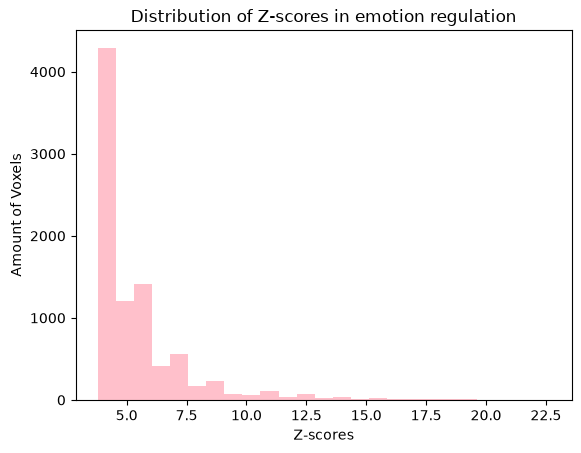

In [10]:
plt.hist(positive_data, bins = 25, color = 'pink') #Create a pink histogram with 25 bins

plt.title('Distribution of Z-scores in emotion regulation'), #Add title and labels
plt.xlabel('Z-scores'), 
plt.ylabel('Amount of Voxels')
plt.show() #Show the histogram
